****

**Nombre:** Juan Martín Cusme Carrera

**Materia:** Recuperación de información

**Curso:** GR1CC

**Fecha:** 28/10/2026

****

# 02 Procesamiento de texto, recuperación secuencial e indexación

## Objetivo

El objetivo fue implementar y comparar la búsqueda secuencial y el índice invertido sobre colecciones de libros del Proyecto Gutenberg. Se investigaron sus tiempos de ejecución y su comportamiento al aumentar el tamaño del corpus.

## Parte A. Corpus pequeño

### 1. Preparación del corpus

Se utilizaron los 18 documentos de la colección Gutenberg disponible en NLTK. Se cargaron los textos originales y se identificaron la cantidad de documentos y sus tamaños. Después se implementaron la tokenización y la normalización mediante la conversión a minúsculas y el tratamiento de la puntuación y los caracteres especiales.

Se seleccionó una configuración de preprocesamiento que se aplicó de la misma manera en todos los experimentos.

#### Configuración del preprocesamiento

Se utilizó la misma función para los dos corpus. Primero se normalizó el texto con NFKC y se convirtió a minúsculas. Después se conservaron solamente las secuencias de letras. La puntuación, los números y los guiones bajos se trataron como separadores de términos.

Se conservaron las tildes y las letras de otros idiomas. Por ejemplo, ÁRBOL quedó como árbol, mientras que las palabras unidas por un guion se separaron.

No se eliminaron las palabras frecuentes ni se redujeron las palabras a sus raíces. Se conservó el texto completo, incluidos los encabezados y las licencias de cada archivo. Por esa razón, algunas coincidencias correspondieron a la información de Gutenberg y no al contenido de la obra.

Para el corpus pequeño se utilizó la colección Gutenberg de NLTK que se había descargado previamente.

In [1]:
import re
import sys
import json
import gc
import unicodedata
import zipfile
import tarfile
from pathlib import Path
from time import perf_counter, perf_counter_ns

import nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psutil
from IPython.display import display

# Permite ejecutar el notebook desde ir26b o desde la carpeta notebooks.
carpeta_actual = Path.cwd()
if (carpeta_actual / "notebooks").is_dir():
    carpeta_proyecto = carpeta_actual
else:
    carpeta_proyecto = carpeta_actual.parent

carpeta_trabajo = carpeta_proyecto / ".venv" / "booleansearch"
carpeta_trabajo.mkdir(parents=True, exist_ok=True)
carpeta_nltk = carpeta_proyecto / ".venv" / "nltk_data"
nltk.data.path.insert(0, str(carpeta_nltk))

try:
    nltk.data.find("corpora/gutenberg")
except LookupError:
    if not nltk.download("gutenberg", download_dir=str(carpeta_nltk), quiet=True):
        raise RuntimeError("No se pudo descargar el corpus Gutenberg de NLTK.")

from nltk.corpus import gutenberg

def tokenizar(texto):
    texto = unicodedata.normalize("NFKC", texto).lower()
    return re.findall(r"[^\W\d_]+", texto)

print(tokenizar("ÁRBOL, don't; hola-mundo 2026 café_azul"))

['árbol', 'don', 't', 'hola', 'mundo', 'café', 'azul']


In [2]:
textos_pequenos = {}
documentos_pequenos = {}
tamanos_pequenos = []

for identificador in gutenberg.fileids():
    texto = gutenberg.raw(identificador)
    tokens = tokenizar(texto)
    textos_pequenos[identificador] = texto
    documentos_pequenos[identificador] = tokens
    tamanos_pequenos.append([
        identificador, len(texto), len(texto.encode("utf-8")), len(tokens)
    ])

tabla_pequena = pd.DataFrame(
    tamanos_pequenos,
    columns=["Documento", "Caracteres", "Bytes UTF-8", "Tokens"]
)
display(tabla_pequena)
print("Número de documentos:", len(documentos_pequenos))
print("Total de tokens:", tabla_pequena["Tokens"].sum())
print("Ejemplo de texto original:", textos_pequenos["austen-emma.txt"][:160])

,Documento,Caracteres,Bytes UTF-8,Tokens
0,austen-emma.txt,887071,887071,161975
1,austen-persuasion.txt,466292,466292,84123
2,austen-sense.txt,673022,673022,120734
3,bible-kjv.txt,4332554,4332554,791842
4,blake-poems.txt,38153,38153,6934
5,bryant-stories.txt,249439,249439,46697
6,burgess-busterbrown.txt,84663,84663,16353
7,carroll-alice.txt,144395,144395,27335
8,chesterton-ball.txt,457450,457455,82785
9,chesterton-brown.txt,406629,406629,73286


Número de documentos: 18
Total de tokens: 2136074
Ejemplo de texto original: [Emma by Jane Austen 1816]

VOLUME I

CHAPTER I


Emma Woodhouse, handsome, clever, and rich, with a comfortable home
and happy disposition, seemed to unite som


### 2. Búsqueda secuencial

Se implementó una función que recibió un término de consulta y devolvió los identificadores de todos los documentos que lo contenían mediante una búsqueda secuencial.

Se utilizaron dos lazos anidados. El primero recorrió los documentos y el segundo recorrió los tokens de cada documento. En esta búsqueda no se utilizaron índices invertidos, motores de búsqueda ni estructuras que almacenaran previamente los documentos asociados a cada término.

Se ejecutaron consultas con términos frecuentes, poco frecuentes e inexistentes.

#### Función de búsqueda secuencial

El primer lazo recorrió los documentos y el segundo recorrió sus tokens. Cuando se encontró el término, se agregó el identificador una sola vez y se continuó con el siguiente documento. Esta función no consultó el índice invertido.

Las funciones de búsqueda recibieron términos que ya se habían normalizado. De esta manera, la tokenización quedó fuera de los tiempos de consulta.

In [3]:
def busqueda_secuencial(termino, documentos):
    resultados = []
    for identificador, tokens in documentos.items():
        for token in tokens:
            if token == termino:
                resultados.append(identificador)
                break
    return resultados

terminos = ["the", "leviathan", "zzzzpalabrainexistentezzzz"]
tipos_terminos = ["Frecuente", "Poco frecuente", "Inexistente"]

for termino, tipo in zip(terminos, tipos_terminos):
    encontrados = busqueda_secuencial(termino, documentos_pequenos)
    print(tipo + ":", termino)
    print("DF:", len(encontrados))
    print("Documentos:", encontrados)
    print()

Frecuente: the
DF: 18
Documentos: ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']

Poco frecuente: leviathan
DF: 3
Documentos: ['bible-kjv.txt', 'melville-moby_dick.txt', 'milton-paradise.txt']

Inexistente: zzzzpalabrainexistentezzzz
DF: 0
Documentos: []



### 3. Medición de tiempos de ejecución

Se utilizó un reloj de alta resolución para medir el tiempo de ejecución de las consultas.

Cada medición correspondió a 30 ejecuciones de la misma consulta y se calculó su media aritmética. Los resultados se registraron en milisegundos. La carga de archivos y la tokenización no se incluyeron dentro del tiempo de consulta.

#### Media de 30 ejecuciones

Se midió cada ejecución en nanosegundos, se convirtió su duración a milisegundos y se calculó la media aritmética. La lectura de archivos, la normalización y la construcción del índice se realizaron antes de medir las consultas.

Los resultados de una consulta no se reutilizaron en las siguientes repeticiones. Cada una de las 30 ejecuciones realizó nuevamente la búsqueda.

In [4]:
REPETICIONES = 30

def medir_tiempo(funcion, *argumentos):
    tiempos = []
    for repeticion in range(REPETICIONES):
        inicio = perf_counter_ns()
        resultado = funcion(*argumentos)
        fin = perf_counter_ns()
        tiempos.append((fin - inicio) / 1_000_000)
    return float(np.mean(tiempos)), resultado

tiempos_secuenciales = []
for termino, tipo in zip(terminos, tipos_terminos):
    tiempo, encontrados = medir_tiempo(
        busqueda_secuencial, termino, documentos_pequenos
    )
    tiempos_secuenciales.append([termino, tipo, len(encontrados), tiempo])

tabla_secuencial = pd.DataFrame(
    tiempos_secuenciales,
    columns=["Término", "Tipo", "DF", "Media secuencial (ms)"]
)
display(tabla_secuencial.round(6))

,Término,Tipo,DF,Media secuencial (ms)
0,the,Frecuente,18,0.016253
1,leviathan,Poco frecuente,3,54.077140
2,zzzzpalabrainexistentezzzz,Inexistente,0,69.969523


### 4. Construcción del índice invertido

Se implementó un índice invertido que contuvo el vocabulario de la colección y las listas de documentos asociados a cada término.

Se inspeccionaron las listas de identificadores y se calculó la frecuencia documental de varios términos. También se implementaron consultas de un término y consultas booleanas con los operadores AND, OR y NOT.

#### Índice invertido y consultas booleanas

Cada término quedó asociado a una lista de identificadores. Durante la construcción del índice se eliminaron las repeticiones de cada término dentro de un mismo libro, de manera que cada identificador apareció una sola vez en su lista.

La frecuencia documental correspondió a la cantidad de documentos asociados al término y no a la cantidad de veces que la palabra apareció en los textos.

El operador AND obtuvo la intersección de los resultados y OR obtuvo su unión. NOT obtuvo los documentos del subconjunto que no contenían el término consultado. Este último se utilizó como operador de un solo término. Los resultados de las consultas booleanas se ordenaron para facilitar su comparación.

In [5]:
def construir_indice(documentos):
    indice = {}
    for identificador, tokens in documentos.items():
        for termino in set(tokens):
            if termino not in indice:
                indice[termino] = []
            indice[termino].append(identificador)
    return indice

def busqueda_indice(termino, indice):
    # Se devuelve una copia para incluir la entrega de los identificadores.
    return list(indice.get(termino, []))

inicio = perf_counter()
indice_pequeno = construir_indice(documentos_pequenos)
tiempo_indice_pequeno = perf_counter() - inicio

print("Términos diferentes:", len(indice_pequeno))
print("Construcción del índice (s):", round(tiempo_indice_pequeno, 3))
for termino in terminos:
    postings = busqueda_indice(termino, indice_pequeno)
    print("Término:", termino, "- DF:", len(postings))
    print("Postings:", postings)

Términos diferentes: 41509
Construcción del índice (s): 0.329
Término: the - DF: 18
Postings: ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']
Término: leviathan - DF: 3
Postings: ['bible-kjv.txt', 'melville-moby_dick.txt', 'milton-paradise.txt']
Término: zzzzpalabrainexistentezzzz - DF: 0
Postings: []


In [6]:
def consultar(consulta, documentos, indice=None):
    operacion, termino1, termino2 = consulta

    if indice is None:
        resultado1 = busqueda_secuencial(termino1, documentos)
    else:
        resultado1 = busqueda_indice(termino1, indice)

    if operacion == "TERMINO":
        return resultado1
    if operacion == "NOT":
        return sorted(set(documentos) - set(resultado1))
    if operacion not in ["AND", "OR"]:
        raise ValueError("El operador debe ser TERMINO, AND, OR o NOT.")

    if indice is None:
        resultado2 = busqueda_secuencial(termino2, documentos)
    else:
        resultado2 = busqueda_indice(termino2, indice)

    if operacion == "AND":
        return sorted(set(resultado1) & set(resultado2))
    return sorted(set(resultado1) | set(resultado2))

consultas = {
    "the": ("TERMINO", "the", None),
    "leviathan": ("TERMINO", "leviathan", None),
    "inexistente": ("TERMINO", "zzzzpalabrainexistentezzzz", None),
    "the AND leviathan": ("AND", "the", "leviathan"),
    "the OR leviathan": ("OR", "the", "leviathan"),
    "NOT the": ("NOT", "the", None)
}

for nombre, consulta in consultas.items():
    encontrados = consultar(consulta, documentos_pequenos, indice_pequeno)
    print(nombre, "->", encontrados)

the -> ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']
leviathan -> ['bible-kjv.txt', 'melville-moby_dick.txt', 'milton-paradise.txt']
inexistente -> []
the AND leviathan -> ['bible-kjv.txt', 'melville-moby_dick.txt', 'milton-paradise.txt']
the OR leviathan -> ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.tx

### 5. Comparación de los métodos

Se ejecutaron las mismas consultas con la búsqueda secuencial y el índice invertido. Se comprobó que ambos métodos recuperaron exactamente los mismos identificadores de documentos y se midió el tiempo medio de 30 ejecuciones para cada consulta y método.

In [7]:
comparacion_pequena = []

for nombre, consulta in consultas.items():
    tiempo_sec, resultado_sec = medir_tiempo(
        consultar, consulta, documentos_pequenos
    )
    tiempo_ind, resultado_ind = medir_tiempo(
        consultar, consulta, documentos_pequenos, indice_pequeno
    )
    iguales = set(resultado_sec) == set(resultado_ind)
    assert iguales, "Los resultados no coinciden en " + nombre
    comparacion_pequena.append([
        nombre, len(resultado_sec), tiempo_sec, tiempo_ind, iguales
    ])

tabla_comparacion_pequena = pd.DataFrame(
    comparacion_pequena,
    columns=["Consulta", "Documentos recuperados", "Secuencial (ms)",
             "Índice (ms)", "Mismos identificadores"]
)
display(tabla_comparacion_pequena.round(6))

,Consulta,Documentos recuperados,Secuencial (ms),Índice (ms),Mismos identificadores
0,the,18,0.012780,0.001287,True
1,leviathan,3,51.347597,0.000950,True
2,inexistente,0,70.977977,0.001157,True
3,the AND leviathan,3,50.611643,0.003163,True
4,the OR leviathan,18,48.991290,0.005663,True
5,NOT the,0,0.020677,0.005647,True


#### Interpretación del corpus pequeño

La búsqueda secuencial y el índice recuperaron los mismos documentos en las consultas realizadas. Las comprobaciones incluidas en el código confirmaron esa igualdad.

La consulta con un término inexistente obligó a la búsqueda secuencial a revisar todos los tokens. En las consultas con palabras frecuentes, el recorrido se detuvo cuando se encontró la primera coincidencia de cada documento.

El índice evitó repetir el recorrido completo de los tokens durante las consultas, aunque su construcción requirió tiempo y memoria adicionales. En las consultas AND, OR y NOT también se incluyó el tiempo de combinación de los resultados. El complemento de NOT se calculó únicamente sobre el corpus consultado.

## Parte B. Corpus grande

### 6. Archivo de Gutenberg

Se utilizó el archivo oficial txt-files.tar.zip, de aproximadamente 11 GB, que ya se había descargado desde el sitio de Gutenberg.

https://www.gutenberg.org/cache/epub/feeds/

Se identificaron los archivos TXT, se evitó contar distintas versiones del mismo identificador como documentos independientes y se registró la cantidad de documentos válidos.

#### Lectura del archivo local y selección de libros

Se utilizó el ZIP que ya se había descargado y se recorrió el TAR que contenía. El TAR no se guardó completo ni se extrajeron todos los libros al disco.

Se consideró válido cada archivo TXT regular que tuvo un tamaño mayor que cero y un nombre con un identificador de Gutenberg. La regla de selección conservó la primera versión encontrada de cada identificador. No se agruparon ediciones o traducciones que tuvieron identificadores distintos.

El conteo correspondió a esas condiciones de los archivos. No se realizó una revisión de su contenido literario ni una comprobación de su idioma.

Se guardaron los primeros 1.000 identificadores distintos encontrados. La muestra quedó determinada por el orden del archivo y no por una selección aleatoria. Los subconjuntos posteriores conservaron los identificadores originales y quedaron incluidos unos dentro de otros.

Se guardó un resumen del recorrido para permitir la reutilización de la muestra en ejecuciones posteriores.

In [8]:
ruta_zip = carpeta_proyecto / "notebooks" / "txt-files.tar.zip"
carpeta_muestra = carpeta_trabajo / "muestra_txt"
carpeta_muestra.mkdir(exist_ok=True)
ruta_resumen = carpeta_trabajo / "resumen_archivo.json"
LIMITE_DOCUMENTOS = 1000

if not ruta_zip.is_file():
    raise FileNotFoundError("Coloca txt-files.tar.zip en la carpeta notebooks.")

firma_archivo = [ruta_zip.stat().st_size, ruta_zip.stat().st_mtime_ns]
resumen = {}
if ruta_resumen.is_file():
    resumen = json.loads(ruta_resumen.read_text(encoding="utf-8"))

reutilizar_muestra = (
    resumen.get("firma") == firma_archivo
    and resumen.get("limite") == LIMITE_DOCUMENTOS
    and all((carpeta_muestra / f"pg{i}.txt").is_file()
            for i in resumen.get("ids_muestra", []))
)

if not reutilizar_muestra:
    libros_validos = {}
    ids_muestra = []
    cantidad_txt = 0
    versiones_validas = 0
    descartados = 0
    inicio = perf_counter()

    with zipfile.ZipFile(ruta_zip) as archivo_zip:
        nombre_tar = next(n for n in archivo_zip.namelist() if n.endswith(".tar"))
        bytes_tar = archivo_zip.getinfo(nombre_tar).file_size
        with archivo_zip.open(nombre_tar) as contenido_tar:
            with tarfile.open(fileobj=contenido_tar, mode="r|") as archivo_tar:
                for miembro in archivo_tar:
                    if not miembro.isfile() or not miembro.name.lower().endswith(".txt"):
                        continue
                    cantidad_txt += 1
                    nombre = Path(miembro.name).name.lower()
                    coincidencia = re.fullmatch(r"(?:pg)?(\d+)(?:-\d+)?\.txt", nombre)
                    if miembro.size == 0 or coincidencia is None:
                        descartados += 1
                        continue

                    identificador = int(coincidencia.group(1))
                    versiones_validas += 1
                    if identificador in libros_validos:
                        continue
                    libros_validos[identificador] = {
                        "ruta": miembro.name, "bytes": miembro.size
                    }

                    if len(ids_muestra) < LIMITE_DOCUMENTOS:
                        datos = archivo_tar.extractfile(miembro).read()
                        destino = carpeta_muestra / f"pg{identificador}.txt"
                        destino.write_bytes(datos)
                        ids_muestra.append(identificador)

                    if len(libros_validos) % 10000 == 0:
                        print("Libros distintos revisados:", len(libros_validos), flush=True)

    resumen = {
        "firma": firma_archivo,
        "limite": LIMITE_DOCUMENTOS,
        "txt_encontrados": cantidad_txt,
        "descartados": descartados,
        "documentos_validos": len(libros_validos),
        "versiones_duplicadas": versiones_validas - len(libros_validos),
        "ids_muestra": ids_muestra,
        "bytes_tar": bytes_tar,
        "segundos_recorrido": perf_counter() - inicio
    }
    ruta_resumen.write_text(json.dumps(resumen, indent=2), encoding="utf-8")
    del libros_validos
else:
    print("Se reutiliza la muestra local ya preparada.")

ids_muestra = resumen["ids_muestra"]
display(pd.DataFrame([{
    "Archivos TXT": resumen["txt_encontrados"],
    "Descartados": resumen["descartados"],
    "Versiones duplicadas": resumen["versiones_duplicadas"],
    "Documentos válidos distintos": resumen["documentos_validos"],
    "Libros de la muestra": len(ids_muestra)
}]))
print("Primeros IDs originales de la muestra:", ids_muestra[:10])
print("Recorrido inicial del archivo (s):", round(resumen["segundos_recorrido"], 2))

Libros distintos revisados: 10000


Libros distintos revisados: 20000


Libros distintos revisados: 30000


Libros distintos revisados: 40000


Libros distintos revisados: 50000


Libros distintos revisados: 60000


Libros distintos revisados: 70000


,Archivos TXT,Descartados,Versiones duplicadas,Documentos válidos distintos,Libros de la muestra
0,78145,0,0,78145,1000


Primeros IDs originales de la muestra: [10000, 10001, 10002, 10003, 10004, 10005, 10006, 10007, 10008, 10009]
Recorrido inicial del archivo (s): 314.85


### 7. Recuperación sobre el corpus grande

Se reutilizaron las funciones desarrolladas en la Parte A. Los documentos se procesaron con la misma configuración de normalización y se construyó el índice invertido de cada subconjunto.

Se ejecutaron las consultas mediante búsqueda secuencial y mediante el índice, se midieron sus tiempos y se comprobó la igualdad de los resultados.

Se trabajó con subconjuntos de tamaños crecientes, se conservaron los identificadores originales y se registraron los recursos de memoria y almacenamiento utilizados.

#### Preprocesamiento y recursos utilizados

Los archivos TXT se decodificaron con UTF-8. Se incluyó una alternativa de lectura con Latin-1 para los archivos que no admitieran esa codificación, aunque ninguno de los archivos de la muestra necesitó esa alternativa.

Se aplicó la misma función de tokenización que se había utilizado en NLTK. Para ahorrar memoria se reutilizaron las cadenas iguales, sin cambiar sus valores ni eliminar tokens.

Se mantuvieron en memoria los tokens de los 1.000 libros y se construyó un solo índice a la vez. La memoria registrada correspondió a la memoria residente del proceso de Python en ese momento e incluyó el notebook y sus bibliotecas. Esa medición no representó el tamaño aislado del índice ni el máximo exacto de memoria del programa.

In [9]:
documentos_grandes = {}
recursos_documentos = []
cantidad_latin1 = 0
inicio = perf_counter()

for identificador in ids_muestra:
    ruta = carpeta_muestra / f"pg{identificador}.txt"
    datos = ruta.read_bytes()
    try:
        texto = datos.decode("utf-8-sig")
    except UnicodeDecodeError:
        texto = datos.decode("latin-1")
        cantidad_latin1 += 1
    tokens = tokenizar(texto)
    if not tokens:
        raise ValueError(f"El documento {identificador} no contiene palabras.")
    documentos_grandes[identificador] = [sys.intern(token) for token in tokens]
    recursos_documentos.append([identificador, len(datos), len(tokens)])

tabla_documentos_grandes = pd.DataFrame(
    recursos_documentos, columns=["ID Gutenberg", "Bytes TXT", "Tokens"]
)
del datos, texto, tokens
gc.collect()

display(tabla_documentos_grandes.head(5))
print("Libros procesados:", len(documentos_grandes))
print("Total de tokens:", tabla_documentos_grandes["Tokens"].sum())
print("Archivos leídos con Latin-1:", cantidad_latin1)
print("Preprocesamiento (s):", round(perf_counter() - inicio, 2))
print("ZIP en disco (GB decimales):", round(ruta_zip.stat().st_size / 1e9, 3))
print("TAR interno, sin extraer (GB):", round(resumen["bytes_tar"] / 1e9, 3))
print("Muestra TXT en disco (MB):", round(tabla_documentos_grandes["Bytes TXT"].sum() / 1e6, 2))
print("RAM total del equipo (GB):", round(psutil.virtual_memory().total / 1e9, 2))
print("Memoria residente de Python (MB):", round(psutil.Process().memory_info().rss / 1e6, 2))

,ID Gutenberg,Bytes TXT,Tokens
0,10000,101742,17446
1,10001,50987,8637
2,10002,305330,54609
3,10003,379938,65971
4,10004,301281,52202


Libros procesados: 1000
Total de tokens: 72554090
Archivos leídos con Latin-1: 0
Preprocesamiento (s): 118.08
ZIP en disco (GB decimales): 11.323
TAR interno, sin extraer (GB): 30.623
Muestra TXT en disco (MB): 426.17
RAM total del equipo (GB): 16.79
Memoria residente de Python (MB): 1129.34


#### Comparación en subconjuntos crecientes

Se utilizaron 50, 100, 250, 500 y 1.000 libros. Para cada tamaño se construyó el índice una vez y se ejecutaron las mismas seis consultas de la Parte A. Cada método se midió 30 veces por consulta. El tiempo de construcción se registró por separado y no se sumó al tiempo de búsqueda mediante el índice.

La consulta inexistente también se utilizó como consulta fija en el análisis de escalabilidad. Se había elegido antes de medir porque obligó a la búsqueda secuencial a recorrer todos los tokens. Los resultados describieron ese caso particular y no el comportamiento de todas las consultas posibles.

En este equipo, la primera ejecución completa tomó aproximadamente 19 minutos. Se dejó preparado un resumen para evitar la repetición del recorrido del ZIP en ejecuciones posteriores. La tokenización y las repeticiones secuenciales requirieron varios minutos. Las tablas y las gráficas de la ejecución quedaron guardadas en el notebook.

In [10]:
tamanos = [50, 100, 250, 500, 1000]
comparacion_grande = []
recursos_grandes = []

if len(documentos_grandes) < max(tamanos):
    raise ValueError("No hay suficientes libros para los tamaños seleccionados.")

for n in tamanos:
    identificadores = ids_muestra[:n]
    subconjunto = {i: documentos_grandes[i] for i in identificadores}
    total_tokens = sum(len(tokens) for tokens in subconjunto.values())
    bytes_textos = int(tabla_documentos_grandes.iloc[:n]["Bytes TXT"].sum())

    inicio = perf_counter()
    indice_actual = construir_indice(subconjunto)
    construccion_ms = (perf_counter() - inicio) * 1000
    memoria_mb = psutil.Process().memory_info().rss / 1e6
    postings_totales = sum(len(lista) for lista in indice_actual.values())
    recursos_grandes.append([
        n, total_tokens, len(indice_actual), postings_totales,
        bytes_textos / 1e6, construccion_ms, memoria_mb
    ])

    for nombre, consulta in consultas.items():
        tiempo_sec, resultado_sec = medir_tiempo(consultar, consulta, subconjunto)
        tiempo_ind, resultado_ind = medir_tiempo(
            consultar, consulta, subconjunto, indice_actual
        )
        iguales = set(resultado_sec) == set(resultado_ind)
        assert iguales, f"Diferencias con {n} documentos en {nombre}"
        if nombre == "inexistente":
            assert resultado_sec == [], "El término elegido sí aparece en el corpus."
        comparacion_grande.append([
            n, total_tokens, nombre, len(resultado_sec),
            tiempo_sec, tiempo_ind, iguales
        ])

    print("Subconjunto terminado:", n, "libros", flush=True)
    del indice_actual, subconjunto
    gc.collect()

tabla_comparacion_grande = pd.DataFrame(
    comparacion_grande,
    columns=["Documentos", "Tokens", "Consulta", "Documentos recuperados",
             "Secuencial (ms)", "Índice (ms)", "Mismos identificadores"]
)
tabla_recursos = pd.DataFrame(
    recursos_grandes,
    columns=["Documentos", "Tokens", "Vocabulario", "Entradas de postings",
             "TXT (MB)", "Construcción índice (ms)", "Memoria Python (MB)"]
)
display(tabla_comparacion_grande.round(6))
display(tabla_recursos.round(3))

Subconjunto terminado: 50 libros


Subconjunto terminado: 100 libros


Subconjunto terminado: 250 libros


Subconjunto terminado: 500 libros


Subconjunto terminado: 1000 libros


,Documentos,Tokens,Consulta,Documentos recuperados,Secuencial (ms),Índice (ms),Mismos identificadores
0,50,2396333,the,50,0.008530,0.001047,True
1,50,2396333,leviathan,4,117.526407,0.000850,True
2,50,2396333,inexistente,0,117.304380,0.000763,True
3,50,2396333,the AND leviathan,4,105.091617,0.004847,True
4,50,2396333,the OR leviathan,50,106.726233,0.006947,True
5,50,2396333,NOT the,0,0.016483,0.005300,True
6,100,5747686,the,100,0.017457,0.001390,True
7,100,5747686,leviathan,5,292.290793,0.000970,True
8,100,5747686,inexistente,0,283.356293,0.000790,True
9,100,5747686,the AND leviathan,5,274.147533,0.008813,True


,Documentos,Tokens,Vocabulario,Entradas de postings,TXT (MB),Construcción índice (ms),Memoria Python (MB)
0,50,2396333,59582,276170,14.268,269.199,1131.307
1,100,5747686,105648,606258,33.617,586.069,1133.240
2,250,18613820,298428,1777252,110.257,2803.774,1162.473
3,500,35663450,392129,3399779,208.748,4644.095,1194.308
4,1000,72554090,646526,6814134,426.175,9275.318,1249.743


#### Interpretación del corpus grande

Las tablas mostraron que los dos métodos recuperaron los mismos identificadores para cada consulta y tamaño. El corpus completo se contó durante el recorrido del archivo, mientras que los tiempos de búsqueda correspondieron únicamente a los subconjuntos de la muestra.

El vocabulario y las asociaciones entre términos y documentos mostraron que el índice también requirió recursos. Su construcción tuvo un costo inicial que se realizó antes de medir las consultas.

El operador NOT necesitó formar el complemento de los resultados dentro del subconjunto. Por esa razón, su procedimiento incluyó un trabajo adicional al de la consulta de un solo término.

## Parte C. Análisis experimental de escalabilidad

### 8. Tiempo de ejecución según el tamaño del corpus

Se seleccionaron cinco tamaños crecientes del corpus grande: 50, 100, 250, 500 y 1.000 documentos.

Para cada tamaño se ejecutó la misma consulta mediante búsqueda secuencial, se repitió 30 veces y se calculó su tiempo promedio. También se utilizó el índice invertido correspondiente al subconjunto y se midió la misma consulta durante 30 ejecuciones. Se registraron ambos tiempos y el número total de tokens.

Se elaboró una gráfica del tiempo medio de ejecución según el número de documentos. El número de documentos se colocó en el eje horizontal y el tiempo en milisegundos en el eje vertical. Los dos métodos se representaron en la misma gráfica.

#### Resultados de la consulta fija

Se reutilizaron las mediciones de la consulta inexistente de la Parte B. Cada valor correspondió a 30 ejecuciones por método y tamaño. No se repitieron las mediciones para seleccionar los tiempos que parecieran mejores.

La carga de archivos, la tokenización y la construcción del índice quedaron fuera de estas mediciones.

,Documentos,Tokens,Secuencial (ms),Índice (ms)
0,50,2396333,117.304380,0.000763
1,100,5747686,283.356293,0.000790
2,250,18613820,964.803057,0.000673
3,500,35663450,1810.541320,0.000820
4,1000,72554090,2344.989233,0.000510


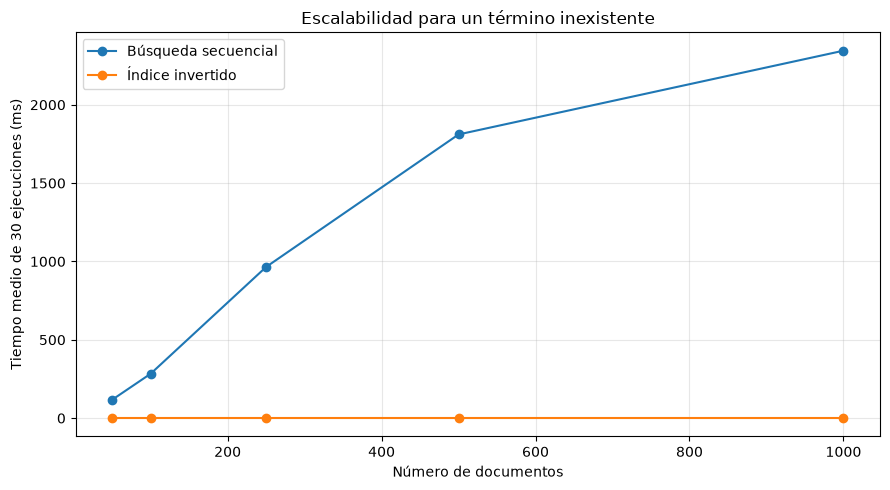

In [11]:
tabla_escalabilidad = tabla_comparacion_grande[
    tabla_comparacion_grande["Consulta"] == "inexistente"
].copy().reset_index(drop=True)

display(tabla_escalabilidad[
    ["Documentos", "Tokens", "Secuencial (ms)", "Índice (ms)"]
].round(6))

plt.figure(figsize=(9, 5))
plt.plot(tabla_escalabilidad["Documentos"], tabla_escalabilidad["Secuencial (ms)"],
         marker="o", label="Búsqueda secuencial")
plt.plot(tabla_escalabilidad["Documentos"], tabla_escalabilidad["Índice (ms)"],
         marker="o", label="Índice invertido")
plt.xlabel("Número de documentos")
plt.ylabel("Tiempo medio de 30 ejecuciones (ms)")
plt.title("Escalabilidad para un término inexistente")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 9. Estimación de una función de tiempo

Se utilizaron los resultados experimentales para estimar la relación entre el número de documentos y el tiempo de cada método de recuperación.

Como primera aproximación se realizó un ajuste lineal por mínimos cuadrados. Se estimaron una pendiente y un valor inicial para cada método, se reportó el coeficiente de determinación y se representaron las rectas ajustadas junto a los datos experimentales.

Se analizó qué tan bien representó el modelo lineal las mediciones y cómo se relacionaron los resultados con el trabajo realizado por cada algoritmo.

Secuencial: t(n) = (2.367634624)n + (204.497699613) ms; R² = 0.9122
Índice: t(n) = (-0.000000242)n + (0.000803361) ms; R² = 0.5642


,Método,a (ms/documento),b (ms),R²
0,Secuencial,2.367635e+00,204.497700,0.912182
1,Índice,-2.420000e-07,0.000803,0.564232


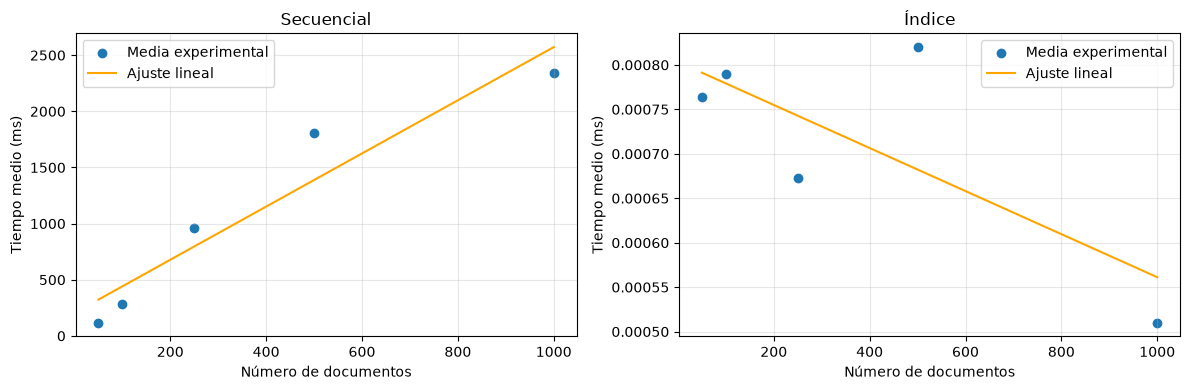

In [12]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

X = tabla_escalabilidad[["Documentos"]]
ajustes = []
predicciones_ajuste = {}

for nombre, columna in [("Secuencial", "Secuencial (ms)"), ("Índice", "Índice (ms)")]:
    y = tabla_escalabilidad[columna]
    modelo = LinearRegression()
    modelo.fit(X, y)
    predicciones = modelo.predict(X)
    predicciones_ajuste[nombre] = predicciones
    a = modelo.coef_[0]
    b = modelo.intercept_
    r2 = r2_score(y, predicciones)
    ajustes.append([nombre, a, b, r2])
    print(f"{nombre}: t(n) = ({a:.9f})n + ({b:.9f}) ms; R² = {r2:.4f}")

tabla_ajustes = pd.DataFrame(
    ajustes, columns=["Método", "a (ms/documento)", "b (ms)", "R²"]
)
display(tabla_ajustes.round(9))

plt.figure(figsize=(12, 4))
for i, (nombre, columna) in enumerate(
    [("Secuencial", "Secuencial (ms)"), ("Índice", "Índice (ms)")], start=1
):
    plt.subplot(1, 2, i)
    plt.scatter(tabla_escalabilidad["Documentos"], tabla_escalabilidad[columna],
                label="Media experimental")
    plt.plot(tabla_escalabilidad["Documentos"], predicciones_ajuste[nombre],
             color="orange", label="Ajuste lineal")
    plt.title(nombre)
    plt.xlabel("Número de documentos")
    plt.ylabel("Tiempo medio (ms)")
    plt.legend()
    plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Guardar las mediciones permite revisar las conclusiones sin repetir el experimento.
tabla_comparacion_pequena.to_csv(carpeta_trabajo / "comparacion_pequena.csv", index=False)
tabla_comparacion_grande.to_csv(carpeta_trabajo / "comparacion_grande.csv", index=False)
tabla_recursos.to_csv(carpeta_trabajo / "recursos.csv", index=False)
tabla_escalabilidad.to_csv(carpeta_trabajo / "escalabilidad.csv", index=False)
tabla_ajustes.to_csv(carpeta_trabajo / "ajustes.csv", index=False)

## Interpretación de los resultados

**¿Cuántos documentos se encontraron y qué se comparó?**

En el archivo se encontraron 78.145 archivos TXT y 78.145 identificadores válidos distintos. Ningún archivo se descartó por las reglas utilizadas y no se encontraron versiones repetidas del mismo identificador. Los tiempos correspondieron a una muestra de 1.000 libros y a sus subconjuntos, no a búsquedas sobre todos los libros del archivo.

En el corpus de NLTK, el término the apareció en los 18 documentos, leviathan apareció en tres y el término inexistente no apareció en ninguno.

**¿Los dos métodos recuperaron lo mismo?**

Los identificadores coincidieron en las seis consultas del corpus pequeño y en las 30 combinaciones de consulta y tamaño del corpus grande. La comparación se realizó mediante conjuntos de identificadores, de modo que el orden no afectó el resultado.

**¿Qué ocurrió con el tiempo al aumentar el corpus?**

Con 1.000 libros y 72.554.090 tokens, la consulta inexistente tardó en promedio 2344.989233 milisegundos mediante búsqueda secuencial y 0.000510 milisegundos mediante el índice. Cada valor correspondió a la media de 30 ejecuciones.

La construcción del índice de ese subconjunto tardó 9275.318 milisegundos y se midió por separado. La ventaja observada en el tiempo de consulta no eliminó el costo de construir el índice.

**¿Cuáles fueron las funciones de tiempo estimadas?**

Para la búsqueda secuencial se obtuvo una pendiente de 2.36763462 milisegundos por documento y un valor inicial de 204.4977 milisegundos. El coeficiente de determinación fue de 0.9122.

Para el índice se obtuvo una pendiente negativa de 0.000000242178 milisegundos por documento y un valor inicial de 0.000803360973 milisegundos. El coeficiente de determinación fue de 0.5642.

El ajuste secuencial explicó gran parte de la variación observada, aunque la gráfica mostró diferencias visibles respecto a la recta. Los libros tuvieron distintas cantidades de tokens, por lo que el número de documentos no describió por completo la longitud de los recorridos.

El ajuste del índice explicó una parte menor de sus pequeñas variaciones. La pendiente y el valor inicial describieron solamente las cinco medias observadas. La pendiente negativa no demostró que el tiempo disminuyera siempre al aumentar la cantidad de documentos ni que el programa necesitara un tiempo negativo.

**¿Cómo se relacionaron los resultados con el trabajo de los algoritmos?**

Para el término ausente, la búsqueda secuencial recorrió todos los tokens. Por eso el trabajo realizado dependió de la cantidad total de tokens y no solamente del número de libros. En las consultas con términos frecuentes, el recorrido se detuvo después de encontrar la primera coincidencia de cada documento.

La consulta mediante el índice accedió a la entrada del término en el diccionario y devolvió una copia de sus identificadores asociados. En el caso del término inexistente, esa lista estuvo vacía y no fue necesario recorrer los tokens de los libros.

Las consultas AND y OR combinaron las listas y ordenaron sus resultados. NOT consideró los documentos del subconjunto y ordenó el complemento. Su procedimiento requirió pasos adicionales respecto a la consulta de un solo término.

La construcción del índice recorrió los tokens. La memoria que utilizó estuvo relacionada con el vocabulario y con la cantidad de asociaciones entre términos y documentos.

**¿Qué recursos y limitaciones tuvo el experimento?**

La muestra TXT ocupó 426.17 MB. El ZIP ocupó 11.323 GB y el TAR interno tuvo un tamaño de 30.623 GB. Ese TAR no se guardó completo en disco.

La mayor memoria residente registrada después de construir un índice fue de 1249.74 MB para el proceso de Python. Ese valor incluyó los tokens de la muestra y las bibliotecas. No correspondió al máximo exacto de memoria del programa ni al tamaño aislado del índice.

Las 30 repeticiones redujeron la influencia de una sola ejecución, aunque las mediciones también quedaron sujetas a los efectos de otros procesos, la caché y la resolución del reloj. Solo se ajustaron cinco tamaños y no se realizaron predicciones fuera de ese intervalo.

La muestra quedó determinada por el orden del archivo, no se filtró por idioma y conservó los encabezados y las licencias. Los resultados no demostraron que todas las consultas ni todos los libros tuvieran el mismo comportamiento.